# Лабораторная 2. Классическая обработка изображений

Задание целиком: `labs/lab02/README.md` в репозитории курса.

Ноутбук один на обе части:
- **Часть 1** (после лекции 2): освещённость и шум по всем фото, гистограммы, коррекция яркости, сравнение фильтров;
- **Часть 2** (после лекции 3): выделение животного на фото, проверка маски по разметке, признаки формы.

Как работать:
1. В первой ячейке впишите свой номер варианта.
2. Заполняйте ячейки с пометкой `TODO` сверху вниз. Ячейки без `TODO` уже готовы, их менять не нужно.
3. Пока вы не дошли до части 2, её ячейки можно не трогать: Run All проходит через них без ошибок.
4. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

В Kaggle включите интернет: Settings → Internet → On.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 6   # номер в списке группы
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab02/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: local | папка данных: .../cv-2026-eskov/data
Вариант 06 уже на месте: .../cv-2026-eskov/data/variant_06


данные варианта: .../cv-2026-eskov/data/variant_06
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import time

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from skimage.restoration import estimate_sigma
from skimage.metrics import structural_similarity

IMG_DIR = DATA_DIR / "images"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

labels = pd.read_csv(DATA_DIR / "labels.csv")
print(len(labels), "фото,", labels["breed"].nunique(), "породы:", ", ".join(labels["breed"].unique()))
print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

800 фото, 4 породы: British_Shorthair, german_shorthaired, Russian_Blue, samoyed
OpenCV 4.14.0 | numpy 2.4.6 | pandas 3.1.0


### Общие функции

Готовый код, менять не нужно.

- `load_rgb(filename)` читает фото через Pillow с `.convert("RGB")` (в датасете есть файлы в режимах `L`, `RGBA`, `P`, это вы видели в лабе 1) и уменьшает его так, чтобы длинная сторона стала 512 px. Одинаковый масштаб нужен, чтобы ядро 5×5 действовало на всех фото одинаково.
- `load_trimap(filename, shape)` читает trimap и приводит его к размеру фото через `cv2.INTER_NEAREST`: значения 1, 2, 3 не смешиваются.
- `show_grid(images, titles, ncols, path)` рисует картинки сеткой и, если указан `path`, сохраняет PNG.

In [3]:
MAX_SIDE = 512   # длинная сторона после уменьшения, px


def load_rgb(filename):
    """Фото как RGB uint8, длинная сторона MAX_SIDE."""
    with Image.open(IMG_DIR / filename) as im:
        rgb = np.asarray(im.convert("RGB"))
    h, w = rgb.shape[:2]
    scale = MAX_SIDE / max(h, w)
    size = (round(w * scale), round(h * scale))           # cv2.resize ждёт (ширина, высота)
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(rgb, size, interpolation=interp)


def load_trimap(filename, shape):
    """Trimap того же размера, что фото: 1 = животное, 2 = фон, 3 = граница."""
    with Image.open(TRIMAP_DIR / (Path(filename).stem + ".png")) as im:
        tri = np.asarray(im)
    return cv2.resize(tri, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)


def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    """Картинки сеткой: RGB как есть, 2D-массивы в оттенках серого. path: куда сохранить PNG."""
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        img = np.asarray(img)
        if img.dtype == bool:
            img = img.astype(np.uint8)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=1 if img.max() <= 1 else 255)
        else:
            ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()


example = load_rgb(labels["filename"].iloc[0])
print(labels["filename"].iloc[0], example.shape, example.dtype)

British_Shorthair_2.jpg (512, 460, 3) uint8


# Часть 1. Освещённость, шум, фильтры

Делается после лекции 2. Результат части: четыре числа по каждому фото, гистограммы, сравнение способов поправить тёмные фото и сравнение фильтров на зашумлённых фото. Из этой части дальше понадобится одна переменная `BEST_FILTER`.

## 1.1 Четыре числа по каждому фото

| Число | Что показывает | Как считать |
|---|---|---|
| `mean_L` | средняя яркость | среднее канала L из `cv2.COLOR_RGB2LAB` (в 8-битном OpenCV L идёт от 0 до 255) |
| `std_L` | контраст | стандартное отклонение того же канала |
| `noise_sigma` | оценка шума в единицах яркости | `estimate_sigma(gray)` из `skimage.restoration` |
| `sharpness` | резкость: у размытого кадра мало перепадов | дисперсия `cv2.Laplacian(gray, cv2.CV_64F)` |

Допишите функцию `image_stats`. Следующая ячейка готова: она пройдёт по всем фото и сохранит `results/part1_stats.csv`.

In [4]:
def image_stats(rgb):
    """Словарь {"mean_L", "std_L", "noise_sigma", "sharpness"} для одного кадра."""
    L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    return {
        "mean_L": float(L.mean()),
        "std_L": float(L.std()),
        "noise_sigma": float(estimate_sigma(gray)),
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
    }

In [5]:
rows = []
for r in labels.itertuples():
    with Image.open(IMG_DIR / r.filename) as im:
        width, height = im.size                      # исходный размер файла
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "width": width, "height": height, **image_stats(load_rgb(r.filename))})
stats = pd.DataFrame(rows)
stats.to_csv(RESULTS / "part1_stats.csv", index=False, float_format="%.4f")
stats.describe().round(2)

,width,height,mean_L,std_L,noise_sigma,sharpness
count,800.00,800.00,800.00,800.00,800.00,800.00
mean,441.72,403.11,125.59,57.91,1.58,721.27
std,85.50,85.64,29.52,13.81,1.34,907.05
min,194.00,196.00,41.38,19.76,0.00,9.20
25%,375.00,333.00,108.26,49.06,0.72,209.18
50%,500.00,375.00,126.49,58.55,1.13,435.94
75%,500.00,500.00,144.33,67.77,1.97,880.45
max,1200.00,900.00,228.18,102.28,9.62,11083.36


In [6]:
by_breed = stats.groupby("breed")[["mean_L", "std_L", "noise_sigma", "sharpness"]].mean().round(2)
print("темнее всех:", by_breed["mean_L"].idxmin(), "| ниже всех резкость:", by_breed["sharpness"].idxmin())
by_breed

темнее всех: samoyed | ниже всех резкость: British_Shorthair


,mean_L,std_L,noise_sigma,sharpness
breed,,,,
British_Shorthair,124.08,56.94,1.22,460.09
Russian_Blue,128.42,57.79,1.28,587.30
german_shorthaired,127.24,59.27,2.26,1261.54
samoyed,122.64,57.65,1.55,576.15


## 1.2 Гистограммы

Нужен один рисунок `results/histograms.png`: распределение `mean_L` по всем фото и гистограммы каналов R, G, B самого тёмного и самого светлого фото. Рядом с гистограммами удобно показать сами фото.

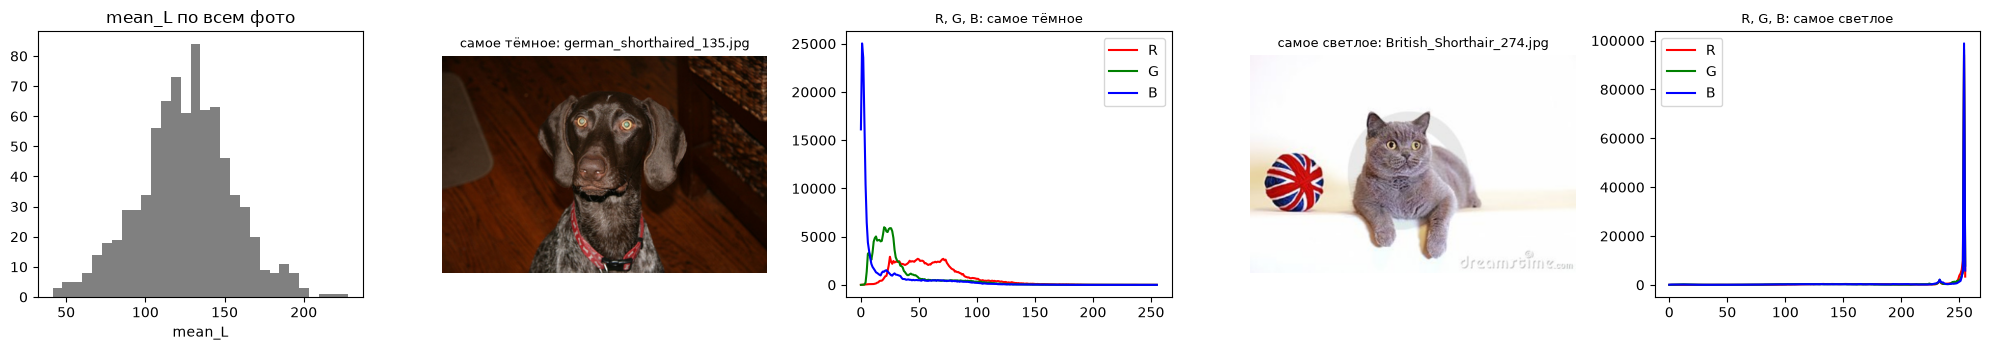

In [7]:
dark_fn = stats.loc[stats["mean_L"].idxmin(), "filename"]
light_fn = stats.loc[stats["mean_L"].idxmax(), "filename"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
axes[0].hist(stats["mean_L"], bins=30, color="gray")
axes[0].set_title("mean_L по всем фото")
axes[0].set_xlabel("mean_L")
for j, (fn, tag) in enumerate([(dark_fn, "самое тёмное"), (light_fn, "самое светлое")]):
    img = load_rgb(fn)
    axes[1 + 2 * j].imshow(img)
    axes[1 + 2 * j].axis("off")
    axes[1 + 2 * j].set_title(f"{tag}: {fn}", fontsize=9)
    for c, col in enumerate(["r", "g", "b"]):
        axes[2 + 2 * j].plot(np.bincount(img[..., c].ravel(), minlength=256), color=col, label=col.upper())
    axes[2 + 2 * j].set_title(f"R, G, B: {tag}", fontsize=9)
    axes[2 + 2 * j].legend()
plt.tight_layout()
plt.savefig(RESULTS / "histograms.png", dpi=100)
plt.show()

## 1.3 Освещённость

Возьмите 5 самых тёмных фото и сравните четыре способа их поправить:

| Метод | Что делает |
|---|---|
| `eq_rgb` | `cv2.equalizeHist` по каждому каналу R, G, B отдельно |
| `eq_L` | `cv2.equalizeHist` только по каналу L в Lab, каналы a и b не трогаем |
| `clahe_L` | CLAHE по каналу L: `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` |
| `gamma` | гамма-коррекция `255 * (x / 255) ** γ`; при γ < 1 тёмные места светлеют сильнее светлых |

Для каждого фото и метода нужны `mean_L` и `std_L` после коррекции и сдвиг цвета: насколько изменились каналы a и b в Lab. Функция `color_shift` готова.

In [8]:
def color_shift(before, after):
    """Средний сдвиг цвета |Δa| + |Δb| в Lab между двумя RGB-кадрами. 0 = оттенки не изменились."""
    lab0 = cv2.cvtColor(before, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab1 = cv2.cvtColor(after, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.abs(lab1[..., 1:] - lab0[..., 1:]).sum(axis=2).mean())

In [9]:
GAMMA = 0.5   # можно подобрать своё значение
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))


def correct(rgb, method):
    """method: "eq_rgb", "eq_L", "clahe_L" или "gamma". Возвращает RGB uint8 того же размера."""
    if method == "eq_rgb":
        return cv2.merge([cv2.equalizeHist(ch) for ch in cv2.split(rgb)])
    if method in ("eq_L", "clahe_L"):
        L, a, b = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))
        L = cv2.equalizeHist(L) if method == "eq_L" else CLAHE.apply(L)
        return cv2.cvtColor(cv2.merge([L, a, b]), cv2.COLOR_LAB2RGB)
    if method == "gamma":
        lut = np.array([255 * (i / 255) ** GAMMA for i in range(256)]).round().astype(np.uint8)
        return cv2.LUT(rgb, lut)
    raise ValueError(method)

,mean_L,std_L,color_shift
method,,,
clahe_L,64.33,52.34,0.38
eq_L,129.67,71.61,0.69
eq_rgb,136.39,70.63,16.86
gamma,101.21,43.74,6.55
original,44.90,40.99,0.00


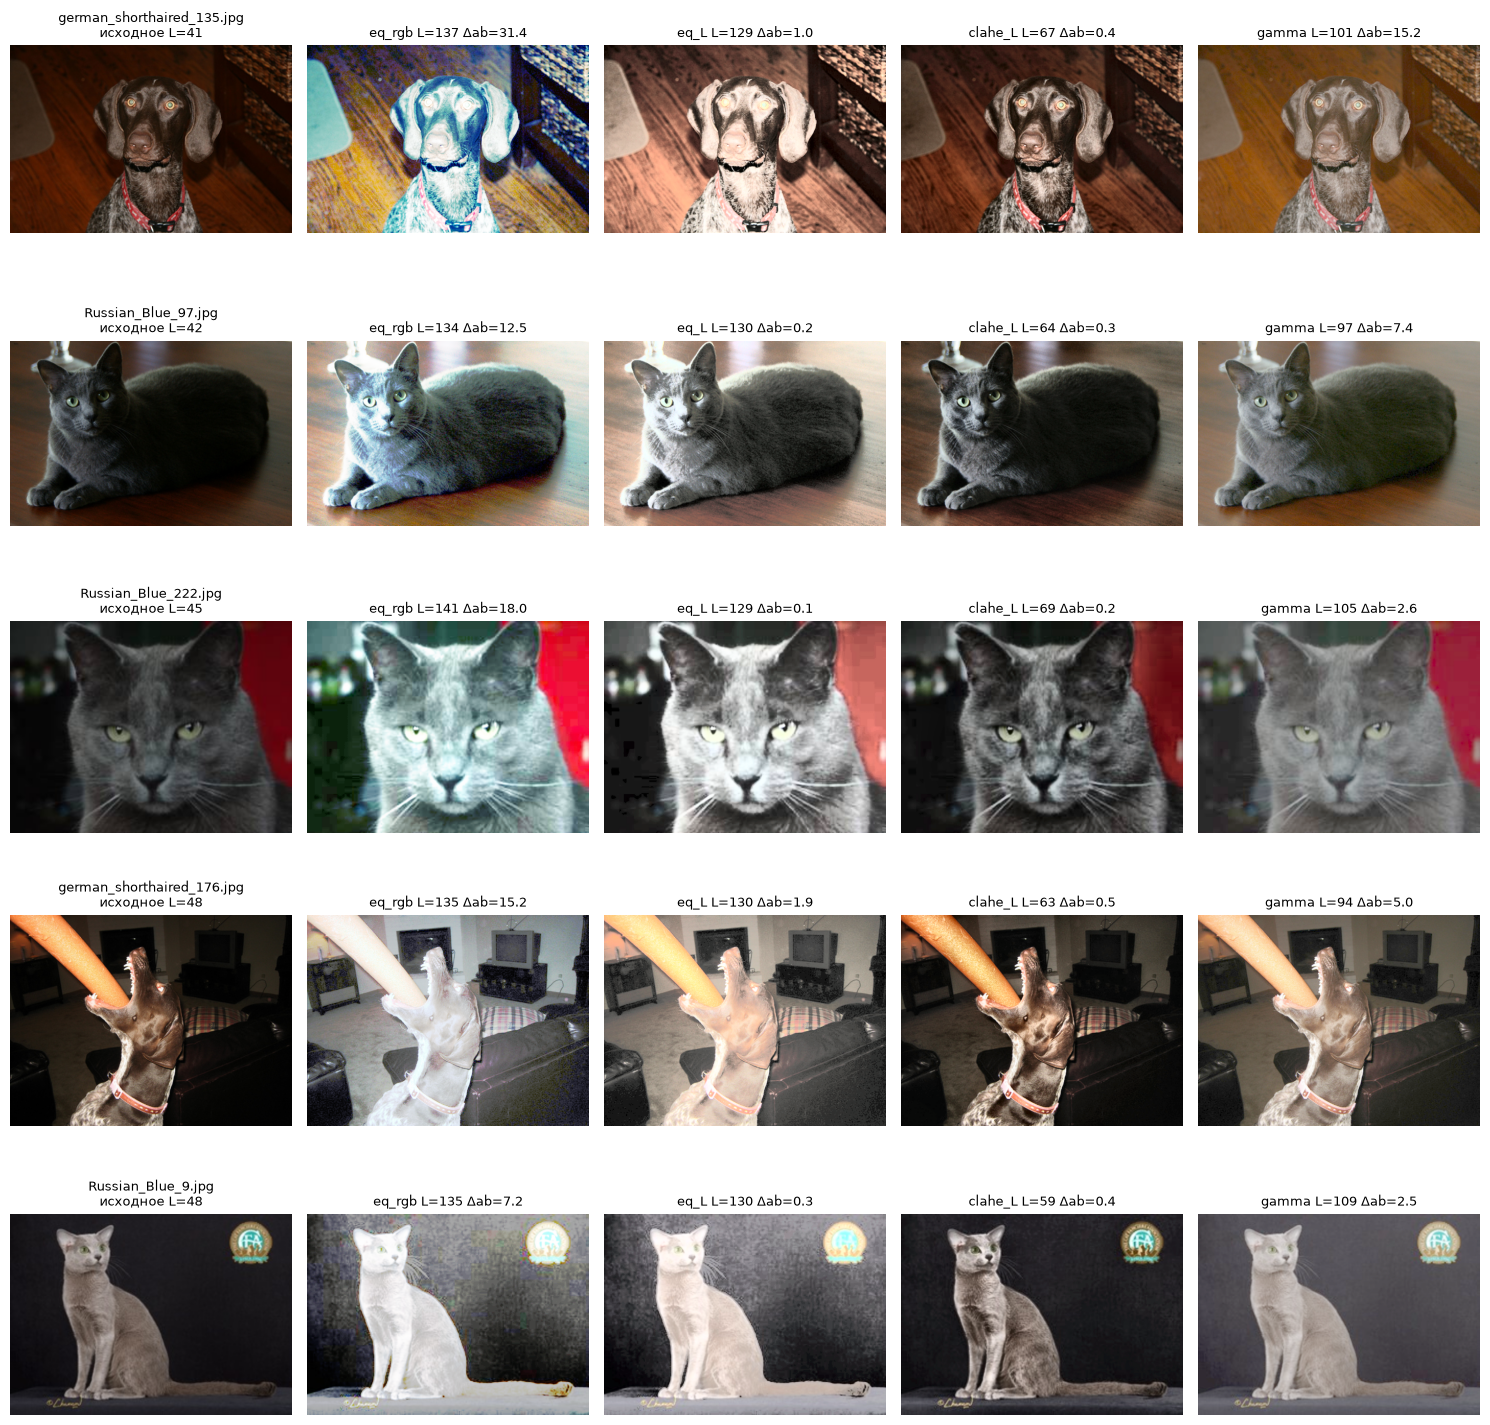

In [10]:
METHODS = ["eq_rgb", "eq_L", "clahe_L", "gamma"]

darkest = stats.nsmallest(5, "mean_L")["filename"].tolist()
rows, panels, titles = [], [], []
for fn in darkest:
    img = load_rgb(fn)
    s = image_stats(img)
    rows.append({"filename": fn, "method": "original", "mean_L": s["mean_L"], "std_L": s["std_L"], "color_shift": 0.0})
    panels.append(img)
    titles.append(f"{fn}\nисходное L={s['mean_L']:.0f}")
    for m in METHODS:
        out = correct(img, m)
        s = image_stats(out)
        cs = color_shift(img, out)
        rows.append({"filename": fn, "method": m, "mean_L": s["mean_L"], "std_L": s["std_L"], "color_shift": cs})
        panels.append(out)
        titles.append(f"{m} L={s['mean_L']:.0f} Δab={cs:.1f}")
illum = pd.DataFrame(rows)
display(illum.groupby("method")[["mean_L", "std_L", "color_shift"]].mean().round(2))
show_grid(panels, titles, ncols=5, path=RESULTS / "illumination.png")

## 1.4 Свёртка руками

`cv2.blur(img, (3, 3))` усредняет каждый пиксель с восемью соседями. То же самое делает свёртка `cv2.filter2D` с ядром 3×3, в котором все девять чисел равны 1/9. Проверьте это на любом фото.

In [11]:
img = load_rgb(labels["filename"].iloc[0])
kernel = np.ones((3, 3), np.float32) / 9
a = cv2.filter2D(img, -1, kernel).astype(int)
b = cv2.blur(img, (3, 3)).astype(int)
print("максимум |filter2D - blur|:", np.abs(a - b).max())

максимум |filter2D - blur|: 0


## 1.5 Шум и фильтры

У каждого варианта свой шум, он задан в `NOISE_PLAN`:

- `gauss`: к каждому пикселю добавлено случайное число из нормального распределения со стандартным отклонением `sigma` (в единицах яркости 0..255);
- `sp` («соль и перец»): доля `amount` пикселей стала чисто чёрной или чисто белой;
- `mix`: оба шума сразу.

Шум добавляется к 30 случайным фото варианта. Фильтр получает зашумлённое фото, результат сравнивается с исходным:

- PSNR в децибелах (`cv2.PSNR`): чем больше, тем ближе к исходному;
- SSIM от 0 до 1 (`structural_similarity`): похожесть по локальной структуре, ближе к тому, что видит глаз;
- время на кадр в миллисекундах.

Сравните `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur` с ядрами 3, 5, 7 и `cv2.bilateralFilter`. По желанию добавьте `cv2.fastNlMeansDenoisingColored`.

In [12]:
NOISE_PLAN = {
    0: {"kind": "gauss", "sigma": 20},
    1: {"kind": "sp", "amount": 0.05},
    2: {"kind": "mix", "sigma": 15, "amount": 0.03},
    3: {"kind": "gauss", "sigma": 30},
    4: {"kind": "sp", "amount": 0.10},
    5: {"kind": "mix", "sigma": 20, "amount": 0.05},
    6: {"kind": "gauss", "sigma": 10},
    7: {"kind": "sp", "amount": 0.02},
    8: {"kind": "mix", "sigma": 10, "amount": 0.02},
    9: {"kind": "gauss", "sigma": 25},
    10: {"kind": "sp", "amount": 0.08},
    11: {"kind": "mix", "sigma": 15, "amount": 0.05},
    12: {"kind": "gauss", "sigma": 15},
    13: {"kind": "sp", "amount": 0.04},
    14: {"kind": "mix", "sigma": 20, "amount": 0.03},
    15: {"kind": "gauss", "sigma": 30},
    16: {"kind": "sp", "amount": 0.06},
    17: {"kind": "mix", "sigma": 10, "amount": 0.04},
    18: {"kind": "gauss", "sigma": 20},
    19: {"kind": "sp", "amount": 0.03},
    20: {"kind": "mix", "sigma": 25, "amount": 0.05},
    21: {"kind": "gauss", "sigma": 25},
    22: {"kind": "sp", "amount": 0.10},
}


def add_noise(rgb, kind, sigma=0, amount=0.0, seed=0):
    """Зашумлённая копия RGB-кадра. kind: "gauss", "sp" или "mix"."""
    rng = np.random.default_rng(seed)
    out = rgb.astype(np.float32)
    if kind in ("gauss", "mix"):
        out = out + rng.normal(0, sigma, out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if kind in ("sp", "mix"):
        r = rng.random(out.shape[:2])
        out[r < amount / 2] = 0
        out[r > 1 - amount / 2] = 255
    return out

шум варианта: kind=gauss sigma=10


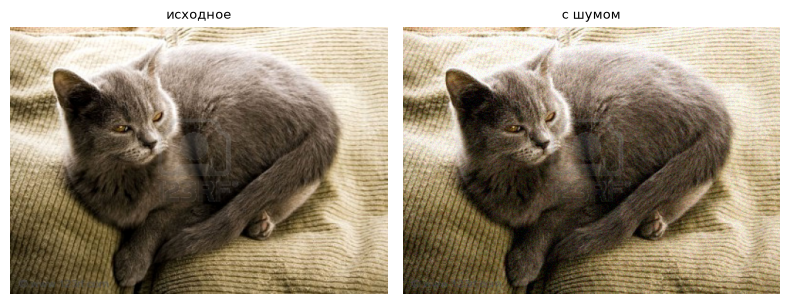

In [13]:
NOISE = NOISE_PLAN[VARIANT]
NOISE_NAME = " ".join(f"{k}={v}" for k, v in NOISE.items())
sample = labels.sample(30, random_state=VARIANT)
clean = [load_rgb(fn) for fn in sample["filename"]]
noisy = [add_noise(img, seed=VARIANT * 100 + i, **NOISE) for i, img in enumerate(clean)]
print("шум варианта:", NOISE_NAME)
show_grid([clean[0], noisy[0]], ["исходное", "с шумом"], ncols=2, size=4)

In [14]:
FILTERS = {
    "blur3": lambda img: cv2.blur(img, (3, 3)),
    "blur5": lambda img: cv2.blur(img, (5, 5)),
    "blur7": lambda img: cv2.blur(img, (7, 7)),
    "gauss3": lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "gauss5": lambda img: cv2.GaussianBlur(img, (5, 5), 0),
    "gauss7": lambda img: cv2.GaussianBlur(img, (7, 7), 0),
    "median3": lambda img: cv2.medianBlur(img, 3),
    "median5": lambda img: cv2.medianBlur(img, 5),
    "median7": lambda img: cv2.medianBlur(img, 7),
    "bilateral": lambda img: cv2.bilateralFilter(img, 9, 75, 75),
    "nlmeans": lambda img: cv2.fastNlMeansDenoisingColored(img, None, 10, 10, 7, 21),
}

In [15]:
def quality(clean_img, out_img):
    """Насколько результат фильтра похож на чистый кадр: {"psnr": ..., "ssim": ...}."""
    return {
        "psnr": float(cv2.PSNR(clean_img, out_img)),
        "ssim": float(structural_similarity(clean_img, out_img, channel_axis=2, data_range=255)),
    }

In [16]:
# Готовый цикл: каждый фильтр на 30 фото, время и качество. "none" = зашумлённое фото без фильтра.
rows = []
for name, f in {"none": lambda img: img, **FILTERS}.items():
    for fn, c, n in zip(sample["filename"], clean, noisy):
        t0 = time.perf_counter()
        out = f(n)
        ms = (time.perf_counter() - t0) * 1000
        rows.append({"filter": name, "filename": fn, "ms": ms, **quality(c, out)})
filt = pd.DataFrame(rows)
filt_summary = filt.groupby("filter").mean(numeric_only=True).round(4)
filt_summary.insert(0, "noise", NOISE_NAME)
filt_summary.to_csv(RESULTS / "filters.csv")
filt_summary

,noise,ms,psnr,ssim
filter,,,,
bilateral,kind=gauss sigma=10,13.4395,33.0520,0.8576
blur3,kind=gauss sigma=10,0.1839,32.2240,0.8520
blur5,kind=gauss sigma=10,0.2221,30.0704,0.8023
blur7,kind=gauss sigma=10,0.3065,28.4395,0.7468
gauss3,kind=gauss sigma=10,0.1103,33.0018,0.8640
gauss5,kind=gauss sigma=10,0.1519,32.2771,0.8639
gauss7,kind=gauss sigma=10,0.2477,30.9773,0.8375
median3,kind=gauss sigma=10,0.1401,31.9093,0.8286
median5,kind=gauss sigma=10,0.9875,30.7740,0.8081


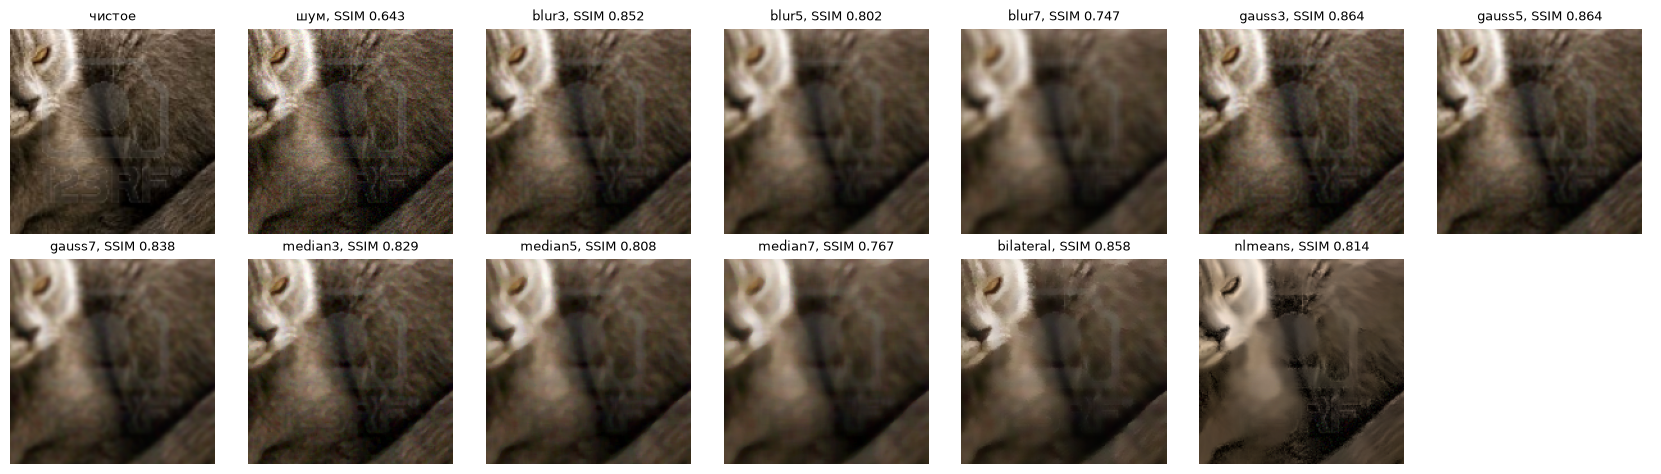

In [17]:
h, w = clean[0].shape[:2]
y0, x0 = h // 2 - 80, w // 2 - 80
crop = lambda img: img[y0:y0 + 160, x0:x0 + 160]
crops = [crop(clean[0]), crop(noisy[0])]
titles = ["чистое", f"шум, SSIM {filt_summary.loc['none', 'ssim']:.3f}"]
for name, f in FILTERS.items():
    crops.append(crop(f(noisy[0])))
    titles.append(f"{name}, SSIM {filt_summary.loc[name, 'ssim']:.3f}")
show_grid(crops, titles, ncols=7, path=RESULTS / "filters.png", size=2.4)

In [18]:
display(filt_summary.sort_values("ssim", ascending=False))
BEST_FILTER = "gauss3"

,noise,ms,psnr,ssim
filter,,,,
gauss3,kind=gauss sigma=10,0.1103,33.0018,0.8640
gauss5,kind=gauss sigma=10,0.1519,32.2771,0.8639
bilateral,kind=gauss sigma=10,13.4395,33.0520,0.8576
blur3,kind=gauss sigma=10,0.1839,32.2240,0.8520
gauss7,kind=gauss sigma=10,0.2477,30.9773,0.8375
median3,kind=gauss sigma=10,0.1401,31.9093,0.8286
nlmeans,kind=gauss sigma=10,187.7160,31.2017,0.8144
median5,kind=gauss sigma=10,0.9875,30.7740,0.8081
blur5,kind=gauss sigma=10,0.2221,30.0704,0.8023


**Почему выбран этот фильтр.** На гауссовом шуме σ = 10 по SSIM победил `gauss3`: 0,864 против 0,643 у фото без фильтра. По PSNR чуть впереди `bilateral` (33,05 дБ против 33,00 дБ), но по SSIM он хуже (0,858) и работает примерно в 100 раз медленнее: 13 мс на кадр против 0,12 мс. На кропах ядро 3×3 почти полностью убирает зерно и сохраняет шерсть. Ядра 5 и 7 уже заметно размывают края, а медиана подходит для «соли и перца», а не для гауссова шума.


# Часть 2 (после лекции 3). Выделение животного и признаки формы

Эту часть делайте после лекции 3. Кто хочет, может сделать её сразу: все функции и подсказки ниже.

Задача: получить маску животного без нейросети. Пайплайн: канал → порог Оцу → полярность → морфология → заливка дыр → самая большая связная компонента → контур и признаки формы. Качество маски проверяем по trimap через IoU, пиксели границы (значение 3) не учитываем.

Из части 1 сюда приходит только `BEST_FILTER`.

In [19]:
def iou_ignore(pred, trimap):
    """IoU маски pred с животным из trimap; пиксели границы (значение 3) не учитываются."""
    valid = trimap != 3
    gt = trimap == 1
    pred = np.asarray(pred) > 0
    inter = np.logical_and(pred, gt)[valid].sum()
    union = np.logical_or(pred, gt)[valid].sum()
    return float(inter / union) if union else float("nan")


def overlay(rgb, mask, color=(0, 255, 0), alpha=0.45):
    """Фото с маской, закрашенной полупрозрачным цветом."""
    out = rgb.copy()
    m = np.asarray(mask) > 0
    out[m] = ((1 - alpha) * out[m] + alpha * np.array(color)).astype(np.uint8)
    return out


# Каналы, из которых можно выбирать. Можно добавить свои.
CHANNELS = {
    "gray": lambda rgb: cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
    "S": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[1],
    "V": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[2],
    "L": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[0],
    "a": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[1],
    "b": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[2],
}

## 2.1 Один кадр по шагам

Пройдите пайплайн на одном фото и сохраните `results/pipeline.png`: исходное фото, trimap, серое, Оцу, после исправления полярности, после морфологии, после заливки и выбора компоненты, контур на фото, адаптивный порог для сравнения. В подписях укажите IoU масок.

Каждый шаг удобно сразу оформить функцией: в 2.2 из них соберётся `segment`.

In [20]:
EXAMPLE = labels["filename"].sample(1, random_state=VARIANT).iloc[0]   # можно заменить на любое фото варианта
rgb = load_rgb(EXAMPLE)
tri = load_trimap(EXAMPLE, rgb.shape)
print(EXAMPLE, rgb.shape, "значения trimap:", np.unique(tri))

British_Shorthair_275.jpg (362, 512, 3) значения trimap: [1 2 3]


порог Оцу: 133.0


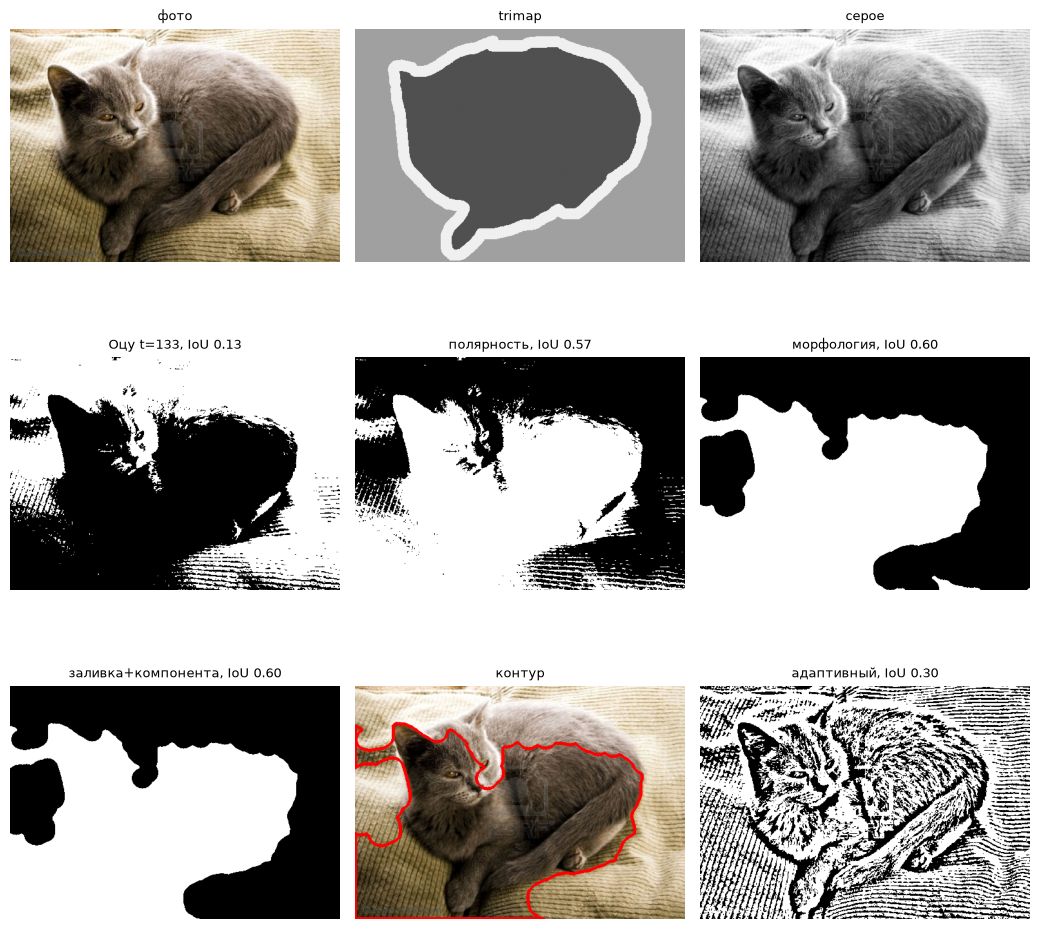

In [21]:
FRAME = 10   # ширина рамки для проверки полярности, px


def otsu(x):
    t, m = cv2.threshold(x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return t, m


def fix_polarity(m):
    """Если рамка кадра в основном белая, белым стал фон: инвертируем."""
    border = np.concatenate([m[:FRAME].ravel(), m[-FRAME:].ravel(), m[:, :FRAME].ravel(), m[:, -FRAME:].ravel()])
    return cv2.bitwise_not(m) if (border > 0).mean() > 0.5 else m


def morph(m, k_open=7, k_close=31):
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_open, k_open)))
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_close, k_close)))


def fill_holes(m):
    padded = cv2.copyMakeBorder(m, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    flood = padded.copy()
    ff_mask = np.zeros((padded.shape[0] + 2, padded.shape[1] + 2), np.uint8)
    cv2.floodFill(flood, ff_mask, (0, 0), 128)
    return np.where(flood[1:-1, 1:-1] == 128, 0, 255).astype(np.uint8)


def largest_component(m):
    n, lab, st, _ = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8))
    if n <= 1:
        return np.zeros_like(m)
    best = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    return np.where(lab == best, 255, 0).astype(np.uint8)


gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
t, m_otsu = otsu(gray)
print("порог Оцу:", t)
m_pol = fix_polarity(m_otsu)
m_morph = morph(m_pol)
m_final = largest_component(fill_holes(m_morph))
contours, _ = cv2.findContours(m_final, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
with_contour = cv2.drawContours(rgb.copy(), contours, -1, (255, 0, 0), 3)
m_adapt = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 5)
show_grid(
    [rgb, tri * 80, gray, m_otsu, m_pol, m_morph, m_final, with_contour, m_adapt],
    ["фото", "trimap", "серое", f"Оцу t={t:.0f}, IoU {iou_ignore(m_otsu, tri):.2f}",
     f"полярность, IoU {iou_ignore(m_pol, tri):.2f}", f"морфология, IoU {iou_ignore(m_morph, tri):.2f}",
     f"заливка+компонента, IoU {iou_ignore(m_final, tri):.2f}", "контур",
     f"адаптивный, IoU {iou_ignore(fix_polarity(m_adapt), tri):.2f}"],
    ncols=3, path=RESULTS / "pipeline.png", size=3.5)

## 2.2 Функция `segment` и выбор канала

`segment` повторяет шаги 2.1 для любого фото. Флаги включают шаги по одному: так в 2.3 будет видно, что даёт каждый. Пока функция не написана, она возвращает пустую маску, и ячейки ниже работают с IoU = 0.

Канал не обязан быть серым: животное может отличаться от фона насыщенностью (`S`) или цветом (`a`, `b`). Сравните минимум два канала из `CHANNELS` готовой функцией `evaluate` и выберите `CHANNEL`. Каждый вызов `evaluate` проходит по всем фото варианта и занимает 10–30 секунд.

In [22]:
def segment(rgb, channel="gray", smooth=True, polarity=True, morph=True, fill=True, k_open=7, k_close=31):
    """Маска животного (bool, размер как у rgb)."""
    if smooth and BEST_FILTER is not None:
        rgb = FILTERS[BEST_FILTER](rgb)
    _, m = otsu(CHANNELS[channel](rgb))
    if polarity:
        m = fix_polarity(m)
    if morph:
        m = globals()["morph"](m, k_open, k_close)
    if fill:
        m = largest_component(fill_holes(m))
    return m > 0

In [23]:
def evaluate(configs):
    """configs: {имя: параметры segment}. Прогоняет segment на всех фото варианта.
    Возвращает таблицу IoU: строка = фото, столбец = имя набора параметров."""
    rows = []
    for fn in labels["filename"]:
        rgb = load_rgb(fn)
        tri = load_trimap(fn, rgb.shape)
        rows.append({"filename": fn, **{name: iou_ignore(segment(rgb, **kw), tri) for name, kw in configs.items()}})
    return pd.DataFrame(rows).set_index("filename")


def summarize(table):
    """Средняя и медианная IoU по каждому столбцу таблицы из evaluate."""
    return pd.DataFrame({"mean_iou": table.mean(), "median_iou": table.median()}).round(3)

In [24]:
ch = evaluate({name: dict(channel=name) for name in ["gray", "S", "a", "b"]})
display(summarize(ch).sort_values("mean_iou", ascending=False))
CHANNEL = "gray"

,mean_iou,median_iou
gray,0.492,0.489
b,0.341,0.212
S,0.338,0.245
a,0.245,0.019


## 2.3 Что даёт каждый шаг

Готовая ячейка: шаги включаются по одному на выбранном канале, результат сохраняется в `results/ablation.csv`.

In [25]:
ABLATION = {
    "1 только Оцу": dict(channel=CHANNEL, smooth=False, polarity=False, morph=False, fill=False),
    "2 + фильтр из части 1": dict(channel=CHANNEL, smooth=True, polarity=False, morph=False, fill=False),
    "3 + полярность": dict(channel=CHANNEL, smooth=True, polarity=True, morph=False, fill=False),
    "4 + морфология": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=False),
    "5 + заливка и компонента": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=True),
}
FINAL = ABLATION["5 + заливка и компонента"]

abl = evaluate(ABLATION)
abl_summary = summarize(abl)
abl_summary.to_csv(RESULTS / "ablation.csv", index_label="step")
print("канал:", CHANNEL, "| фильтр:", BEST_FILTER)
abl_summary

канал: gray | фильтр: gauss3


,mean_iou,median_iou
1 только Оцу,0.253,0.147
2 + фильтр из части 1,0.255,0.147
3 + полярность,0.443,0.428
4 + морфология,0.471,0.452
5 + заливка и компонента,0.492,0.489


## 2.4 Признаки формы

Для итоговой маски каждого фото нужны признаки самого большого внешнего контура:

| Признак | Как считать |
|---|---|
| `area_frac` | `cv2.contourArea(c)` / площадь кадра |
| `perimeter` | `cv2.arcLength(c, True)` |
| `x, y, w, h` | `cv2.boundingRect(c)` |
| `elongation` | длинная сторона / короткая сторона `cv2.minAreaRect(c)[1]` |
| `circularity` | 4π × площадь / периметр²; у круга 1, у вытянутой и рваной фигуры меньше |
| `solidity` | площадь / площадь `cv2.convexHull(c)`; лапы и хвост её уменьшают |

Допишите `shape_features`. Следующая ячейка готова: она соберёт `results/masks.csv` (строка на фото: IoU и признаки).

In [26]:
def shape_features(mask):
    """Признаки формы маски: area_frac, perimeter, x, y, w, h, elongation, circularity, solidity."""
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return {}
    c = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(c)
    perim = cv2.arcLength(c, True)
    x, y, w, h = cv2.boundingRect(c)
    rw, rh = cv2.minAreaRect(c)[1]
    hull = cv2.contourArea(cv2.convexHull(c))
    return {
        "area_frac": area / mask.size,
        "perimeter": perim,
        "x": x, "y": y, "w": w, "h": h,
        "elongation": max(rw, rh) / min(rw, rh) if min(rw, rh) > 0 else float("nan"),
        "circularity": 4 * np.pi * area / perim ** 2 if perim > 0 else float("nan"),
        "solidity": area / hull if hull > 0 else float("nan"),
    }

In [27]:
rows = []
for r in labels.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "iou": iou_ignore(mask, load_trimap(r.filename, rgb.shape)), **shape_features(mask)})
masks = pd.DataFrame(rows)
masks.to_csv(RESULTS / "masks.csv", index=False, float_format="%.4f")
masks.head()

,filename,breed,species,iou,area_frac,perimeter,x,y,w,h,elongation,circularity,solidity
0,British_Shorthair_2.jpg,British_Shorthair,cat,0.995094,0.455040,1625.616436,24,46,402,432,1.057545,0.509625,0.840178
1,British_Shorthair_3.jpg,British_Shorthair,cat,0.000549,0.093089,1205.830515,0,285,512,51,10.357557,0.150349,0.721682
2,British_Shorthair_6.jpg,British_Shorthair,cat,0.953398,0.221717,1066.614348,114,42,267,284,1.612734,0.457675,0.819131
3,British_Shorthair_8.jpg,British_Shorthair,cat,0.525169,0.229119,1732.871269,23,62,319,342,1.311513,0.179675,0.586676
4,British_Shorthair_9.jpg,British_Shorthair,cat,0.829711,0.358434,1380.271202,101,65,346,320,1.081505,0.466037,0.811957


In [28]:
cols = ["iou", "area_frac", "elongation", "circularity", "solidity"]
display(masks.groupby("breed")[cols].mean().round(3))
masks.groupby("species")[cols].mean().round(3)

,iou,area_frac,elongation,circularity,solidity
breed,,,,,
British_Shorthair,0.464,0.434,1.534,0.310,0.716
Russian_Blue,0.475,0.430,1.487,0.301,0.705
german_shorthaired,0.432,0.386,1.492,0.278,0.688
samoyed,0.598,0.394,1.493,0.355,0.742


,iou,area_frac,elongation,circularity,solidity
species,,,,,
cat,0.470,0.432,1.511,0.305,0.711
dog,0.515,0.390,1.493,0.316,0.715


## 2.5 Лучшие и худшие маски

Галерея из 6 лучших и 6 худших масок по IoU сохраняется в `results/best_worst.png`. Посмотрите на худшие: что у них общего (фон того же цвета, что животное, тёмный кадр, ошибка в самой разметке)?

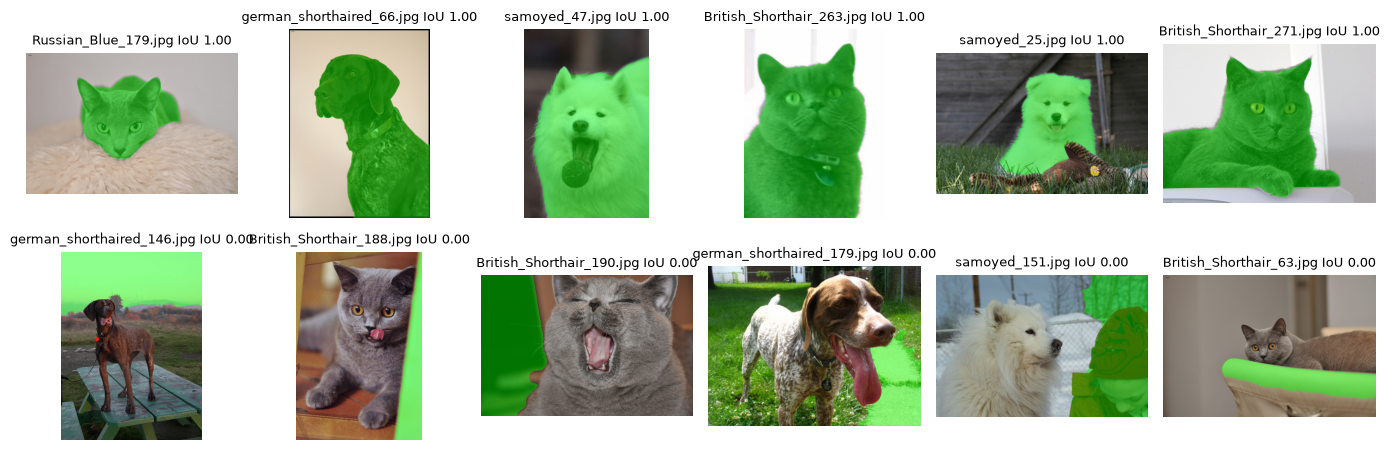

In [29]:
ranked = masks.dropna(subset=["iou"]).sort_values("iou", ascending=False)
panels, titles = [], []
for r in pd.concat([ranked.head(6), ranked.tail(6)]).itertuples():
    img = load_rgb(r.filename)
    panels.append(overlay(img, segment(img, **FINAL)))
    titles.append(f"{r.filename} IoU {r.iou:.2f}")
show_grid(panels, titles, ncols=6, path=RESULTS / "best_worst.png", size=2.3)

## Выгрузка

Ячейка ниже проверяет, что все 9 файлов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab02/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [30]:
print(f"вариант {VARIANT} | шум {NOISE_NAME} | BEST_FILTER = {BEST_FILTER} | CHANNEL = {CHANNEL}")

expected = {"part1_stats.csv", "histograms.png", "illumination.png", "filters.csv", "filters.png",
            "pipeline.png", "ablation.csv", "masks.csv", "best_worst.png"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 9 файлов на месте")

вариант 6 | шум kind=gauss sigma=10 | BEST_FILTER = gauss3 | CHANNEL = gray
не хватает: ничего, все 9 файлов на месте


In [31]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)